# Classifying skill commit messages

We collected the full messages of the 339 commits that changed the ten `SKILL.md` files in the pilot. This notebook uses simple keyword rules to suggest why each commit was made. The labels still need manual review.


## Load the messages

In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

file = Path("../data/gitskills/commit_messages.json")
if not file.exists():
    file = Path("data/gitskills/commit_messages.json")

commits = pd.read_json(file, convert_dates=["committed_at"])
commits[["skill", "committed_at", "subject"]].head()

,skill,committed_at,subject
0,ac27-level-editor,2026-06-01 23:02:10+00:00,"refactor: migrate skills to .claude/skills, ad..."
1,ac27-level-editor,2026-06-02 00:05:19+00:00,"test: audit all tests — add CLI args, deduplic..."
2,ac27-level-editor,2026-06-02 00:19:40+00:00,"refactor: consolidate src/ — fix facade, remov..."
3,ac27-level-editor,2026-06-02 03:41:14+00:00,"fix: validation, display, and UI improvements"
4,ac27-level-editor,2026-06-02 06:23:58+00:00,refactor: ACL as single source of truth — CSV/...


## Classification rules

[Tufano et al.](https://www.inf.usi.ch/faculty/bavota/papers/icse2015_badSmells.pdf) use four commit-goal tags: bug fixing, enhancement, new feature, and refactoring. A commit can have more than one tag. Their study did **not** publish a keyword list for these tags: the authors linked some commits to issues and classified the rest manually using messages and diffs.

The rules below are our own automatic starting point. We use a recognizable prefix first (`fix:`, `feat:`, or `refactor:`). Otherwise, we look for words in the subject and keep every matching tag. `fix:` and `feat:` come from [Conventional Commits](https://www.conventionalcommits.org/en/v1.0.0/); `refactor:` and the keyword lists are our choices. A message with no match stays unclassified.


In [6]:
prefixes = {"fix": "bug fixing", "feat": "new feature", "refactor": "refactoring"}

keywords = {
    "bug fixing": {"fix", "fixed", "fixes", "bug", "bugs", "repair", "correct", "resolve", "resolved"},
    "enhancement": {"improve", "improved", "improvement", "enhance", "enhanced", "optimize", "optimized"},
    "new feature": {"add", "added", "implement", "implemented", "introduce", "introduced", "feature", "features"},
    "refactoring": {"refactor", "refactored", "restructure", "simplify", "cleanup"}
}

def classify(subject):
    text = subject.lower()
    prefix = text.split(":")[0].split("(")[0].rstrip("!")

    if prefix in prefixes:
        return [prefixes[prefix]], "prefix"

    words = set(re.findall(r"[a-z]+", text))
    labels = [label for label, terms in keywords.items() if words & terms]
    return labels, "keyword" if labels else "no match"

commits[["labels", "rule"]] = pd.DataFrame(
    commits["subject"].apply(classify).tolist(), index=commits.index
)
commits[["subject", "labels", "rule"]].head(10)

,subject,labels,rule
0,"refactor: migrate skills to .claude/skills, ad...",[refactoring],prefix
1,"test: audit all tests — add CLI args, deduplic...","[bug fixing, new feature]",keyword
2,"refactor: consolidate src/ — fix facade, remov...",[refactoring],prefix
3,"fix: validation, display, and UI improvements",[bug fixing],prefix
4,refactor: ACL as single source of truth — CSV/...,[refactoring],prefix
5,refactor: comprehensive React best-practices a...,[refactoring],prefix
6,docs: audit & sync README and SKILL.md with co...,[],no match
7,"@ v1.0.8 — approach.js module (State=30), audi...",[],no match
8,@ @ v1.0.8 — saveTime extraction (file truth v...,[bug fixing],keyword
9,"@ v1.0.8 — English UI dialogs, structured erro...",[],no match


## Results

In [7]:
commits["rule"].value_counts()


rule
prefix      181
no match     86
keyword      72
Name: count, dtype: int64

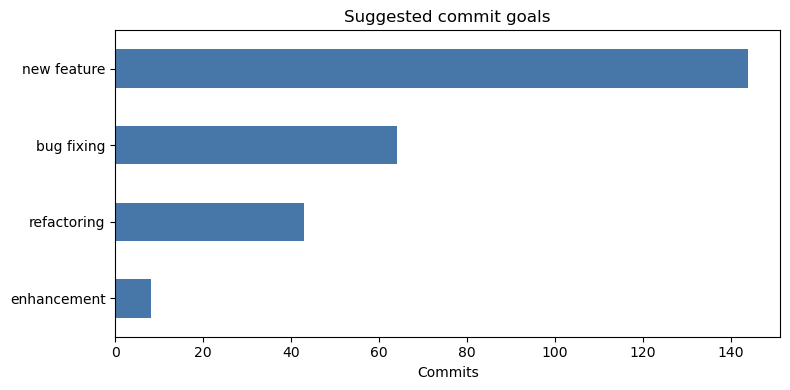

In [8]:
counts = commits.explode("labels")["labels"].value_counts().sort_values()
ax = counts.plot.barh(figsize=(8, 4), color="#4776a8")
ax.set_xlabel("Commits")
ax.set_ylabel("")
ax.set_title("Suggested commit goals")
plt.tight_layout()
plt.show()


## Check some messages

Review messages with no tag or several tags, as well as a sample of the others. The diff is needed to check whether the tag describes the skill file itself.


In [5]:
commits["tag_count"] = commits["labels"].str.len()
review = commits[commits["tag_count"] != 1]
review[["skill", "subject", "labels", "commit_url"]].head(20)

,skill,subject,labels,commit_url
1,ac27-level-editor,"test: audit all tests — add CLI args, deduplic...","[bug fixing, new feature]",https://github.com/ericpzh/AC27LevelEditor/com...
6,ac27-level-editor,docs: audit & sync README and SKILL.md with co...,[],https://github.com/ericpzh/AC27LevelEditor/com...
7,ac27-level-editor,"@ v1.0.8 — approach.js module (State=30), audi...",[],https://github.com/ericpzh/AC27LevelEditor/com...
9,ac27-level-editor,"@ v1.0.8 — English UI dialogs, structured erro...",[],https://github.com/ericpzh/AC27LevelEditor/com...
12,ac27-level-editor,@ v1.0.10 — object-based ACL parser: tokenizer...,[],https://github.com/ericpzh/AC27LevelEditor/com...
14,ac27-level-editor,"v1.0.10 — per-file type resolution, cache-driv...",[],https://github.com/ericpzh/AC27LevelEditor/com...
15,ac27-level-editor,"v1.1.0 — unified cache.json, standalone cache ...",[],https://github.com/ericpzh/AC27LevelEditor/com...
16,ac27-level-editor,chore: bump version references to v1.1.0 in SK...,[],https://github.com/ericpzh/AC27LevelEditor/com...
17,ac27-level-editor,v1.1.1 — stand position map overlay in editor,[],https://github.com/ericpzh/AC27LevelEditor/com...
18,ac27-level-editor,"v1.1.2 — StarMap overlay, State=5 approach air...",[],https://github.com/ericpzh/AC27LevelEditor/com...


## What this tells us

These labels are a first guess based on commit titles. Some commits have more than one label or no label at all. We need to check the messages and `SKILL.md` changes before using them in the analysis.